In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
import os
os.chdir(r'E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets')
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('FMAC-HPI_24420.csv')
df.columns , df.shape

(Index(['Date', 'NSA Value', 'SA Value'], dtype='str'), (531, 3))

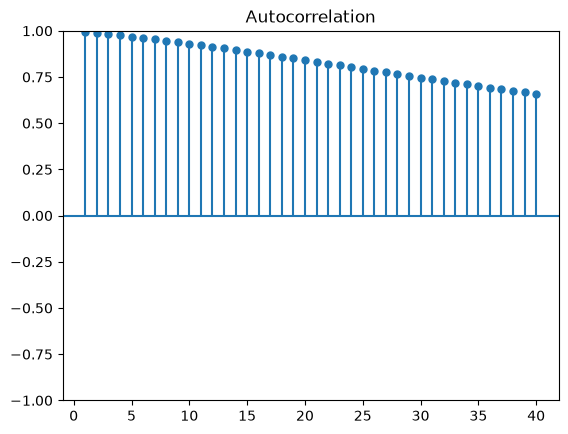

In [5]:
plot_acf(df['NSA Value'], lags=  40 , alpha = None, zero  = False)
plt.show()

In [16]:
y = df['NSA Value']
y_train = y[:-12]
y_test = y[-12:]

In [17]:
# order =   p           d            q
# AR Lags order , Order of diff , Moving Average

model = ARIMA(y_train , order=(2,1,1))
model_fit = model.fit()

print('Coefficient : %s' % model_fit.params)
predictions = model_fit.predict(start = len(y_train), end = len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test, predictions)

print('Test RMSE: %.3f '% error)

Coefficient : ar.L1     1.473144
ar.L2    -0.589775
ma.L1     0.999739
sigma2    0.035254
dtype: float64
Test RMSE: 3.184 


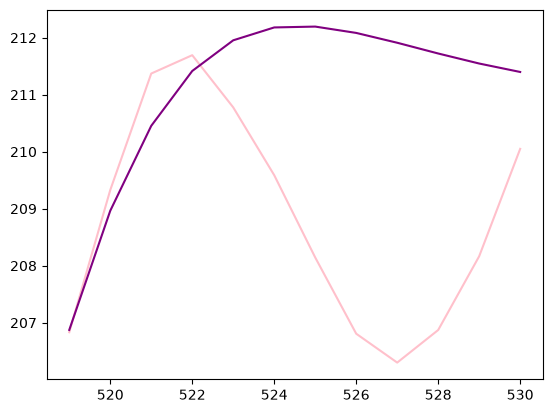

In [18]:
y_test.plot(color = 'pink')
predictions.plot(color = 'purple')
plt.show()

# Auto-ARIMA

In [22]:
# !pip install pmdarima

In [21]:
from pmdarima.arima import auto_arima

In [26]:
model = auto_arima(y_train , trace=True, error_action = 'ignore', suppress_warnings = True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-258.744, Time=0.98 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1625.721, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=545.901, Time=0.14 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.36 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1668.139, Time=0.02 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-211.845, Time=0.73 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.88 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=1.18 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.81 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.71 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.34 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.60 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.40 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=-254.857, Time=0.70 sec

Best model:  ARIMA(2,1,2)(0,0,0)[0] intercept
Total fit time: 11.885 seco

In [27]:
model.bse()

intercept    0.021643
ar.L1        0.050364
ar.L2        0.047876
ma.L1        0.054004
ma.L2        0.054050
sigma2       0.001529
dtype: float64

Coefficient : ar.L1     1.325369
ar.L2    -0.454246
ma.L1     1.225305
ma.L2     0.245904
sigma2    0.034546
dtype: float64
Test RMSE: 3.296 


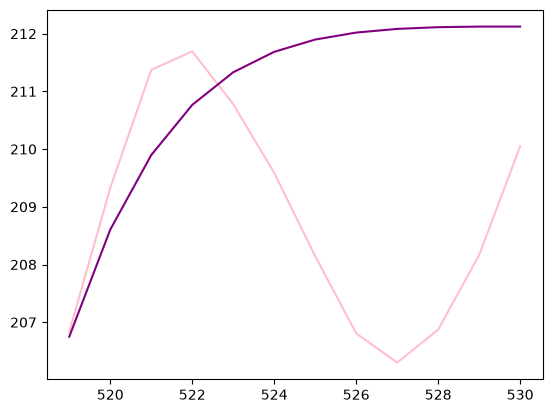

In [29]:

model = ARIMA(y_train , order=(2,1,2))
model_fit = model.fit()

print('Coefficient : %s' % model_fit.params)
predictions = model_fit.predict(start = len(y_train), end = len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test, predictions)

print('Test RMSE: %.3f '% error)

y_test.plot(color = 'pink')
predictions.plot(color = 'purple')
plt.show()